In [1]:
import os
import tarfile
import time
import json
import copy

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as T
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import f1_score, confusion_matrix
from collections import Counter
from pathlib import Path

from torch.utils.data import DataLoader, Subset, random_split

In [3]:
# распаковка архива
archive_path = Path("../CUB_200_2011.tgz")
data_path = Path("../images/birds")

data_path.mkdir(parents=True, exist_ok=True)


with tarfile.open(archive_path, "r:gz") as archive:
    archive.extractall(data_path, filter="data")

print(os.listdir(data_path))

['attributes.txt', 'CUB_200_2011']


In [ ]:
# правильно ли распаковался датасет с фотографиями птиц и сколько видов птиц в нём содержится 🐦:))
dataset_path = "../images/birds/CUB_200_2011/images"

print(os.listdir(dataset_path)[:5])
print("Количество видов птиц:", len(os.listdir(dataset_path)))

['001.Black_footed_Albatross', '002.Laysan_Albatross', '003.Sooty_Albatross', '004.Groove_billed_Ani', '005.Crested_Auklet']
Количество видов птиц: 200


In [5]:
device = torch.device("cpu")

In [6]:
# трансформация изображений
train_transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

valid_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [7]:
# создание датасета и определение классов (кол-во видов птиц, которые нейронка должна распознать)
dataset_path = "../images/birds/CUB_200_2011/images"

train_dataset = torchvision.datasets.ImageFolder(
    dataset_path,
    transform=train_transform
)

valid_dataset = torchvision.datasets.ImageFolder(
    dataset_path,
    transform=valid_transform
)

class_names = train_dataset.classes
num_classes = len(class_names)

print("Количество изображений:", len(train_dataset))
print("Количество видов птиц:", num_classes)
print("Первые 5 видов:", class_names[:5])

Количество изображений: 11788
Количество видов птиц: 200
Первые 5 видов: ['001.Black_footed_Albatross', '002.Laysan_Albatross', '003.Sooty_Albatross', '004.Groove_billed_Ani', '005.Crested_Auklet']


In [8]:
# разделение датасета на обучающую и проверочную выборки
train_size = int(0.8 * len(train_dataset))
valid_size = len(train_dataset) - train_size

torch.manual_seed(42)

indices = torch.randperm(len(train_dataset)).tolist()

train_indices = indices[:train_size]
valid_indices = indices[train_size:]

train_dataset = Subset(train_dataset, train_indices)
valid_dataset = Subset(valid_dataset, valid_indices)

print("Обучающая выборка:", len(train_dataset))
print("Проверочная выборка:", len(valid_dataset))

Обучающая выборка: 9430
Проверочная выборка: 2358


In [9]:
# создание DataLoader для обучения и проверки
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

In [10]:
# проверка загрузки данных
images, labels = next(iter(train_loader))

print("Размер изображений:", images.shape)
print("Размер меток:", labels.shape)

Размер изображений: torch.Size([64, 3, 224, 224])
Размер меток: torch.Size([64])


In [12]:
# загружаем модель
weights = ResNet18_Weights.DEFAULT

model = resnet18(weights=weights)

model = model.to(device)

In [13]:
# настраиваем fine-tuning
# замораживаем все параметры
for param in model.parameters():
    param.requires_grad = False

# размораживаем последний сверточный блок
for param in model.layer4.parameters():
    param.requires_grad = True

# заменяем классификационный слой
model.fc = nn.Linear(
    in_features=512,
    out_features=num_classes
)

In [14]:
# функция потерь и оптимизатор
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.0001
)

In [15]:
# Обучение модели
train_losses, valid_losses = [], []
train_accs, valid_accs = [], []

start_time = time.time()

for epoch in range(3):

    # Обучение
    model.eval()
    model.layer4.train()
    model.fc.train()

    train_loss = 0
    train_correct = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(labels)

        predicted = outputs.argmax(dim=1)
        train_correct += (predicted == labels).sum().item()

    # Валидация
    model.eval()

    valid_loss = 0
    valid_correct = 0

    with torch.inference_mode():

        for images, labels in valid_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            valid_loss += loss.item() * len(labels)

            predicted = outputs.argmax(dim=1)
            valid_correct += (predicted == labels).sum().item()

    # Сохраняем результаты эпохи
    train_losses.append(train_loss / len(train_dataset))
    valid_losses.append(valid_loss / len(valid_dataset))

    train_accs.append(train_correct / len(train_dataset))
    valid_accs.append(valid_correct / len(valid_dataset))

    print(
        f"Эпоха {epoch + 1}: "
        f"train loss={train_losses[-1]:.3f}, "
        f"val loss={valid_losses[-1]:.3f}, "
        f"train acc={train_accs[-1]:.1%}, "
        f"val acc={valid_accs[-1]:.1%}"
    )

training_time = time.time() - start_time

print(f"Время обучения: {training_time:.2f} секунд")

Эпоха 1: train loss=4.396, val loss=3.335, train acc=18.1%, val acc=37.2%
Эпоха 2: train loss=2.850, val loss=2.405, train acc=50.2%, val acc=54.0%
Эпоха 3: train loss=2.043, val loss=1.893, train acc=65.3%, val acc=61.5%
Время обучения: 1286.10 секунд


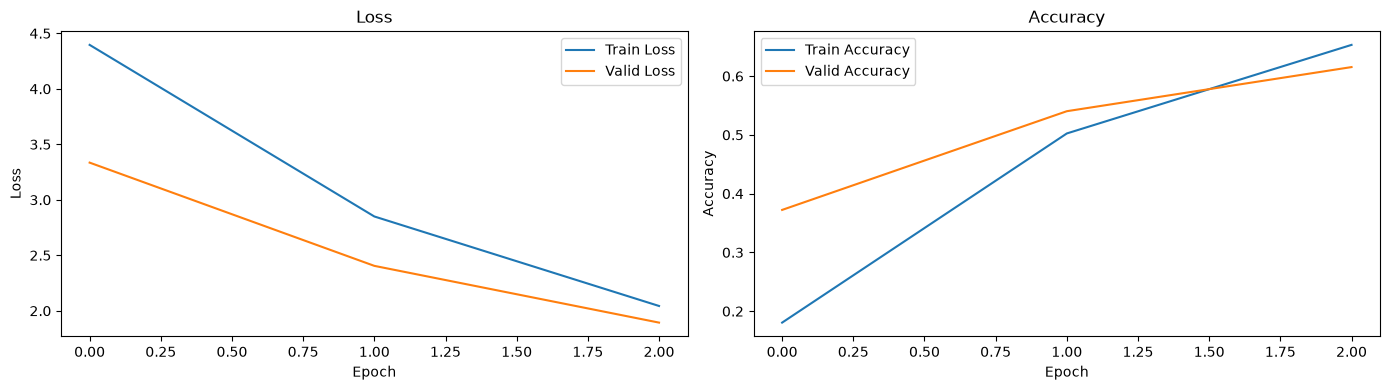

In [16]:
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train Loss")
plt.plot(valid_losses, label="Valid Loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label="Train Accuracy")
plt.plot(valid_accs, label="Valid Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
# Сохраняем модель
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names
}, "../models/bird_resnet18.pth")

In [19]:
# Получаем предсказания
y_true = []
y_pred = []

model.eval()

with torch.inference_mode():

    for images, labels in valid_loader:

        images = images.to(device)

        outputs = model(images)
        predicted = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predicted.cpu().numpy())

In [20]:
# Рассчитываем F1 и confusion matrix
f1 = f1_score(
    y_true,
    y_pred,
    average="weighted"
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(num_classes)
)

print(f"F1-score: {f1:.3f}")

F1-score: 0.604


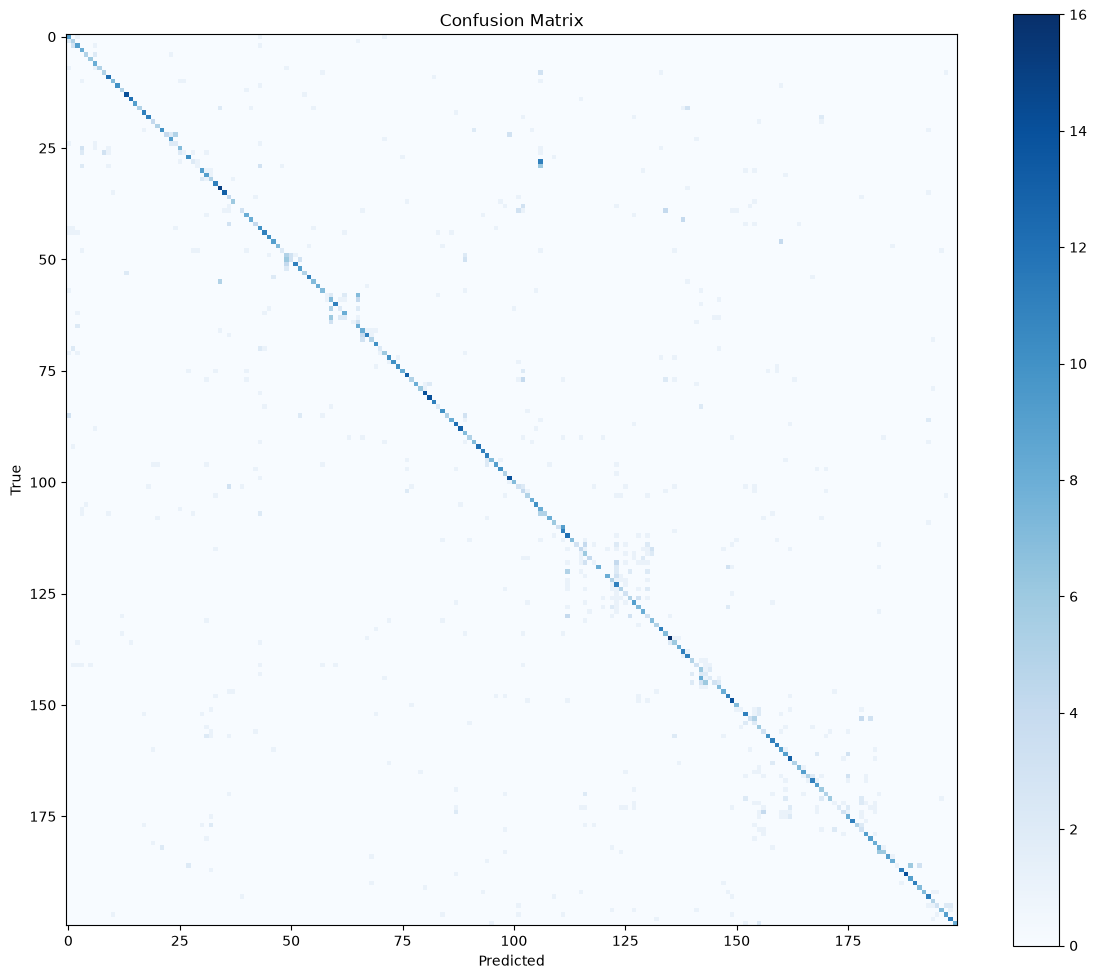

In [21]:
# Визуализируем confusion matrix
plt.figure(figsize=(12, 10))

plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")

plt.colorbar()
plt.tight_layout()
plt.show()

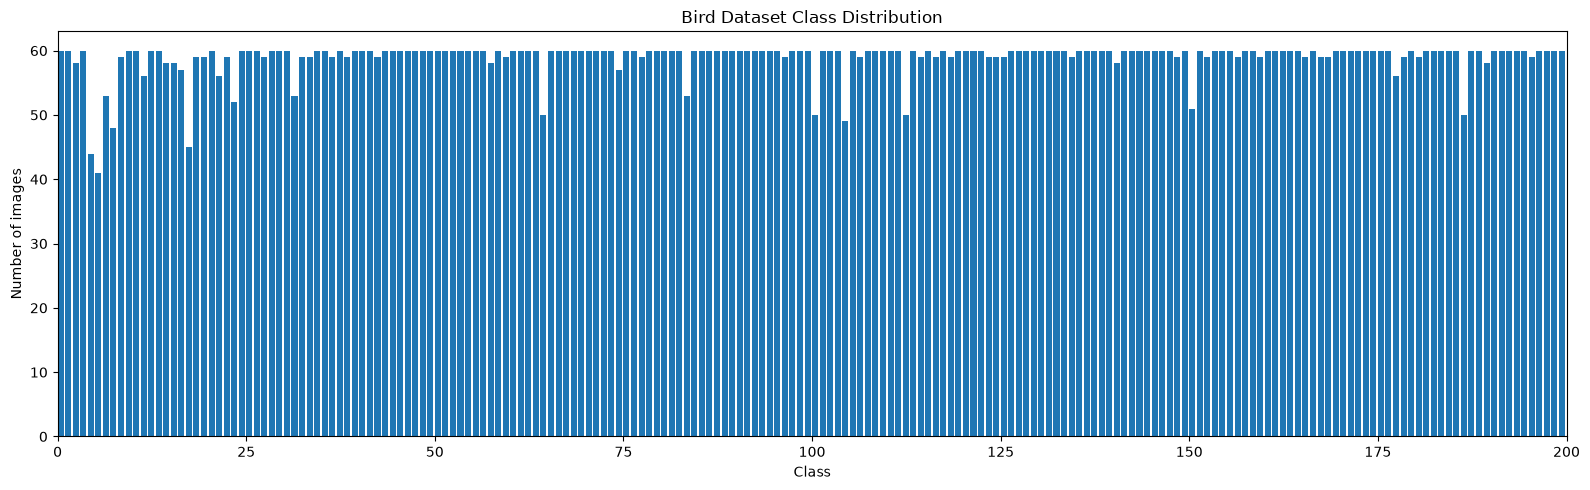

In [26]:
# Распределение изображений по классам
class_counts = Counter(train_dataset.dataset.targets)
# Counter считает сколько изображений относится к каждому классу (виду птиц)

class_distribution = {
    class_names[i]: class_counts[i]
    for i in range(num_classes)
}

plt.figure(figsize=(16, 5))

plt.bar(
    range(num_classes),
    class_distribution.values(),
    align="edge"
)

plt.title("Bird Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xlim(0, num_classes)

plt.tight_layout()
plt.show()

In [ ]:
# # Сохраняем метрики
# metrics = {
#     "train_losses": train_losses,
#     "valid_losses": valid_losses,
#     "train_accs": train_accs,
#     "valid_accs": valid_accs,
#     "training_time": training_time,
#     "dataset_size": len(train_dataset),
#     "train_size": len(train_dataset),
#     "valid_size": len(valid_dataset),
#     "class_names": class_names,
#     "class_distribution": class_distribution,
#     "f1_score": float(f1),
#     "confusion_matrix": cm.tolist()
# }

# with open("../models/bird_metrics.json", "w", encoding="utf-8") as file:
#     json.dump(metrics, file, ensure_ascii=False, indent=4)

# print(f"F1-score: {f1:.3f}")
# print(f"Время обучения: {training_time:.2f} секунд")

F1-score: 0.604
Время обучения: 1286.10 секунд


In [ ]:
# Сохраняем метрики
metrics = {
    "train_losses": train_losses,
    "valid_losses": valid_losses,
    "train_accs": train_accs,
    "valid_accs": valid_accs,
    "training_time": training_time,
    "dataset_size": len(train_dataset) + len(valid_dataset),
    "train_size": len(train_dataset),
    "valid_size": len(valid_dataset),
    "class_names": class_names,
    "class_distribution": class_distribution,
    "f1_score": float(f1),
    "confusion_matrix": cm.tolist()
}

with open("../models/bird_metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, ensure_ascii=False, indent=4)


Метрики сохранены!
